In [26]:
#IMPORTS
from sklearn.preprocessing import PowerTransformer, StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, silhouette_score
import scipy.stats as stats
import seaborn as sns
import pandas as pd
import numpy as np
import itertools
import tqdm
import math
import re
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness, MDS
from sklearn.cluster import HDBSCAN
import gower

In [ ]:
#CONFIGURACOES
# ---- nao truncar impressao do pandas ---- #
#pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
#pd.set_option('display.max_colwidth', None)
# ----------------------------------------- #

In [28]:
df = pd.read_csv("dados/Dados_REG_limpo_baseline.csv", sep="\t")
n = len(df)

PARAM_GRID = {
    "min_cluster_size": [5, 10, 15, 20],
    "min_samples": [2, 3, 4, 5],  
    "cluster_selection_method": ["eom"]
}

SEED = 0
COMPUTE_STABILITY = True
STABILITY_FRAC = 0.7        # fraciona quantas amostras sao usadas do conj. original 
N_JOBS = -1

MIN_CLUSTER_FRAC = 0.05     # menor cluster >= 5% dos dados
MIN_STABILITY = 0.70        # ARI min

# Limpeza das atividades

In [29]:
ensaios = [c for c in df.columns if c.startswith("Atividade")]

In [30]:
#transforma string em binario
for c in ensaios:
    if pd.api.types.is_string_dtype(df[c]):
        df[c] = df[c].map({"Positivo": 1, "Negativo": 0})
df.tail()

,GRAM,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
498,Negativo,4,0.0,1,4,2,0.0,0.0,0,0.0,1,0,0.00,0.00,0.27,0.03,0.50,0.32,0.26,0.24,1,0.0,0.00,1,3,0,1,NaN,NaN,0,3.422
499,Positivo,4,0.0,1,4,2,0.0,0.0,0,1.6,0,0,0.00,0.03,0.01,0.01,0.09,0.31,0.20,0.15,3,0.0,0.00,0,2,2,3,3.0,3.0,2,7.210
500,Positivo,2,1.0,1 & 2,4,2,1.0,0.0,0,2.2,1,0,1.00,0.00,0.24,0.02,0.19,0.40,0.15,0.11,2,0.0,3.75,1,3,3,3,3.0,3.0,3,6.137
501,Positivo,4,0.0,1,1,1,0.0,1.0,0,0.0,1,0,1.17,0.01,-0.06,-0.02,0.57,0.35,0.28,0.23,2,0.0,0.00,1,1,0,3,3.0,1.0,1,5.695
502,Positivo,4,0.0,1,1,2,0.0,0.0,0,0.0,1,0,1.00,0.00,0.17,-0.02,0.69,0.54,0.18,0.10,0,0.0,0.00,1,1,0,0,3.0,0.0,0,27.252


In [31]:
#transforma os nulos em mediana
for c in ["Atividade 20", "Atividade 21"]:
    df[c] = df[c].fillna(df[c].median())

df

,GRAM,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,Negativo,2,0.0,1,1,2,0.0,1.0,0,0.00,0,0,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.00,0.00,1,1,1,3,1.0,3.0,0,2.767
1,Positivo,2,0.0,1,4 & 1,2,0.0,0.0,0,2.33,0,0,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,2.80,3.00,1,3,3,2,3.0,3.0,0,12.678
2,Positivo,2,0.0,2 & 1,4 & 1,2,0.0,0.0,0,3.50,0,0,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,2.00,2.50,1,3,3,3,3.0,3.0,3,6.870
3,Negativo,2,0.0,1,1,2,0.0,1.0,0,0.00,0,0,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.00,0.00,1,0,0,0,0.0,1.0,0,2.728
4,Positivo,3,0.0,1,4 & 1,2,0.0,0.0,0,1.75,0,0,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.20,1,2,3,0,3.0,3.0,3,11.353
5,Positivo,7,0.0,1,1,2,0.0,0.0,0,0.00,0,1,1.25,0.01,0.02,-0.03,0.87,0.48,0.23,0.35,0,0.00,0.00,1,1,0,3,0.0,0.0,0,3.209
6,Negativo,5,0.0,2,4 & 1,2,0.0,0.0,0,2.25,0,0,1.33,0.01,0.11,-0.03,0.29,0.22,0.15,0.19,1,0.00,0.00,1,0,1,0,3.0,3.0,0,16.151
7,Positivo,5,0.0,1,4 & 1,2,0.0,0.0,0,2.50,0,1,1.40,0.00,0.14,-0.01,0.52,0.23,0.16,0.16,1,0.00,0.00,1,0,0,0,0.0,0.0,0,8.512
8,Negativo,2,0.0,1,1,2,0.0,1.0,0,0.00,0,0,1.50,0.01,0.13,0.00,1.36,0.63,0.24,0.05,1,0.00,1.33,1,0,0,3,0.0,0.0,0,2.033
9,Positivo,5,0.0,1,4 & 1,2,0.0,1.0,0,2.25,0,1,1.25,0.01,0.12,-0.01,0.56,0.21,0.17,0.15,1,0.00,0.00,1,0,1,3,1.0,0.0,0,35.659


In [ ]:
#transforma as colunas com multiplos valores em one-hot
multi_cols = ["Cores", "Textura", "Forma", "Brilho"]
parts = []
for c in multi_cols:
    dummies = (
        df[c].astype(str).str.replace(" ", "", regex=False)
        .str.get_dummies(sep="&")
        .add_prefix(f"{c}_")
    )
    parts.append(dummies)
multi = pd.concat(parts, axis=1)
multi

,Cores_1,Cores_2,Cores_3,Cores_4,Cores_5,Cores_6,Cores_7,Textura_1,Textura_2,Forma_1,Forma_2,Forma_4,Forma_6,Brilho_0,Brilho_1,Brilho_2,Brilho_4,GRAM_Levedura,GRAM_Levedura?não,GRAM_Negativo,GRAM_Positivo
0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
1,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
2,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,0,0,0,1
3,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
4,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
5,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,0,1
6,0,0,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0,1,0
7,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
8,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
9,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1


In [33]:
df_copy = df.copy()

df_copy = df_copy.drop(columns=multi_cols)
df_copy = df_copy.join(multi)

df_copy

,Borda,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23,Cores_1,Cores_2,Cores_3,Cores_4,Cores_5,Cores_6,Cores_7,Textura_1,Textura_2,Forma_1,Forma_2,Forma_4,Forma_6,Brilho_0,Brilho_1,Brilho_2,Brilho_4,GRAM_Levedura,GRAM_Levedura?não,GRAM_Negativo,GRAM_Positivo
0,0.0,0.0,1.0,0,0.00,0,0,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.00,0.00,1,1,1,3,1.0,3.0,0,2.767,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
1,0.0,0.0,0.0,0,2.33,0,0,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,2.80,3.00,1,3,3,2,3.0,3.0,0,12.678,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
2,0.0,0.0,0.0,0,3.50,0,0,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,2.00,2.50,1,3,3,3,3.0,3.0,3,6.870,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,0,0,0,1
3,0.0,0.0,1.0,0,0.00,0,0,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.00,0.00,1,0,0,0,0.0,1.0,0,2.728,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
4,0.0,0.0,0.0,0,1.75,0,0,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.20,1,2,3,0,3.0,3.0,3,11.353,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
5,0.0,0.0,0.0,0,0.00,0,1,1.25,0.01,0.02,-0.03,0.87,0.48,0.23,0.35,0,0.00,0.00,1,1,0,3,0.0,0.0,0,3.209,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,0,1
6,0.0,0.0,0.0,0,2.25,0,0,1.33,0.01,0.11,-0.03,0.29,0.22,0.15,0.19,1,0.00,0.00,1,0,1,0,3.0,3.0,0,16.151,0,0,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0,1,0
7,0.0,0.0,0.0,0,2.50,0,1,1.40,0.00,0.14,-0.01,0.52,0.23,0.16,0.16,1,0.00,0.00,1,0,0,0,0.0,0.0,0,8.512,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
8,0.0,0.0,1.0,0,0.00,0,0,1.50,0.01,0.13,0.00,1.36,0.63,0.24,0.05,1,0.00,1.33,1,0,0,3,0.0,0.0,0,2.033,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
9,0.0,0.0,1.0,0,2.25,0,1,1.25,0.01,0.12,-0.01,0.56,0.21,0.17,0.15,1,0.00,0.00,1,0,1,3,1.0,0.0,0,35.659,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1


In [34]:
Categoricos = [c for c in df_copy.columns for d in multi_cols if c.startswith(d) ]
Categoricos.extend([
    "GRAM",
    "Borda",
    "Muco",
    "Relevo",
    "Atividade 01",
    "Atividade 03",
    "Atividade 04",
    "Atividade 16"
                    ])
Categoricos


['Cores_1',
 'Cores_2',
 'Cores_3',
 'Cores_4',
 'Cores_5',
 'Cores_6',
 'Cores_7',
 'Textura_1',
 'Textura_2',
 'Forma_1',
 'Forma_2',
 'Forma_4',
 'Forma_6',
 'Brilho_0',
 'Brilho_1',
 'Brilho_2',
 'Brilho_4',
 'GRAM_Levedura',
 'GRAM_Levedura?não',
 'GRAM_Negativo',
 'GRAM_Positivo',
 'GRAM',
 'Borda',
 'Muco',
 'Relevo',
 'Atividade 01',
 'Atividade 03',
 'Atividade 04',
 'Atividade 16']

In [35]:
#cria a booleana de categoricos
Catval = [c in Categoricos for c in df_copy.columns]
Catval

[True,
 True,
 True,
 True,
 False,
 True,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True]

In [36]:
#Cria gower
D = gower.gower_matrix(df_copy, cat_features=Catval)
D = D.astype(np.float64)
np.fill_diagonal(D, 0)
D

array([[0.        , 0.19758941, 0.23842335, ..., 0.31241423, 0.225437  ,
        0.22351569],
       [0.19758941, 0.        , 0.08058871, ..., 0.17280939, 0.26882726,
        0.19437163],
       [0.23842335, 0.08058871, 0.        , ..., 0.12354624, 0.29232815,
        0.25211409],
       ...,
       [0.31241423, 0.17280939, 0.12354624, ..., 0.        , 0.31283358,
        0.29025072],
       [0.225437  , 0.26882726, 0.29232815, ..., 0.31283358, 0.        ,
        0.13287187],
       [0.22351569, 0.19437163, 0.25211409, ..., 0.29025072, 0.13287187,
        0.        ]], shape=(503, 503))

In [37]:
#HDBSCAN com a gower original

hdbs = HDBSCAN(metric="precomputed", min_cluster_size=15,
                 min_samples=2, copy=True)

labels = hdbs.fit_predict(D)

labels

array([ 0,  2, -1,  0,  1, -1, -1, -1,  0, -1,  0, -1, -1,  1, -1, -1, -1,
       -1,  0, -1,  1, -1,  1, -1,  2, -1,  0,  0, -1, -1, -1, -1, -1,  0,
        0, -1, -1,  0,  0,  0,  1, -1,  0,  0, -1,  0, -1, -1, -1, -1, -1,
       -1,  0,  0, -1, -1, -1, -1, -1,  0,  0,  0, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1,  0, -1,  0,  0, -1, -1, -1, -1, -1,  0,  0,  2, -1,
       -1, -1, -1, -1, -1,  2, -1, -1, -1, -1, -1,  0,  0,  0, -1,  0,  0,
       -1, -1, -1, -1,  0,  0, -1,  0, -1, -1, -1,  0,  0,  0,  0, -1,  0,
        0,  0,  0,  0, -1,  0, -1,  0, -1, -1,  2, -1, -1, -1, -1, -1, -1,
       -1, -1,  0, -1, -1, -1, -1, -1, -1, -1, -1,  2, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  2,  2,  2, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  2,  2, -1, -1,  2, -1, -1, -1,
       -1, -1, -1,  0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1,  0, -1

In [38]:
#SALVA CLASSES ORIGINAIS
classe_OG = pd.DataFrame(labels, columns=["Classe_HDBS_OG"])
classe_OG.to_csv('Classe_HDBS_OG.csv', index=False)
classe_OG

,Classe_HDBS_OG
0,0
1,2
2,-1
3,0
4,1
5,-1
6,-1
7,-1
8,0
9,-1


In [39]:
#reduz as dimensoes pra ver se melhora
teste_MDS = MDS(
    n_components=2, 
    dissimilarity="precomputed",
    random_state=SEED, 
    n_init=1
    ).fit_transform(D)
teste_MDS

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


array([[-0.01270276,  0.06840673],
       [-0.14783846, -0.07685523],
       [-0.17043973, -0.11535237],
       ...,
       [-0.24461762, -0.10505887],
       [-0.0630463 , -0.16095257],
       [ 0.11024512, -0.034861  ]], shape=(503, 2))

In [54]:
#Cria o modelo (usado p/ grid)
def build_model(params):
    return HDBSCAN(
        min_cluster_size=params["min_cluster_size"], 
        min_samples=params["min_samples"], 
        cluster_selection_method=params["cluster_selection_method"], 
        n_jobs=N_JOBS,
        copy=True
    )

#Avalia a qualidade do modelo, comparando com silhuette e gower
def evaluate(params):
    model = build_model(params)

    labels = model.fit_predict(teste_MDS)
    counts = np.bincount(labels[labels != -1])

    sil = np.nan
    mask = labels != -1
    labels_validos = labels[mask]

    # soh calcula silhueta do que nao eh ruido
    if len(np.unique(labels_validos)) > 1:
        sil = silhouette_score(
            D[np.ix_(mask, mask)],
            labels_validos,
            metric="precomputed"
        )
    
    stab = np.nan
    if COMPUTE_STABILITY:
        preds = []

        for seed in (1, 2):
            r = np.random.default_rng(SEED + seed)

            sub = r.choice(n, size=int(n * STABILITY_FRAC), replace=False)

            m = build_model(params)

            #m.fit(teste_MDS[sub])
            preds.append(m.fit_predict(teste_MDS[sub]))

        stab = adjusted_rand_score(preds[0], preds[1])

    return {**params,
            "silhouette_gower": sil,
            "stability_ari": stab,
            "min_cluster_frac": counts.min() / n,
            "labels": model.labels_}

In [ ]:
keys = list(PARAM_GRID)

# "itertools.product" gera todas as combinacoes possiveis de hiperparam.
combos = [dict(zip(keys, v)) for v in itertools.product(*PARAM_GRID.values())]
print(f"{len(combos)} combinações")

results = []
for params in tqdm.tqdm(combos):
    try:
        results.append(evaluate(params))
    except Exception as e:
        print("ERRO", params, e) 

res = pd.DataFrame(results)
res.to_csv("dados/resultados_grid_HDBSCAN.csv", index=False)
res.sort_values("silhouette_gower", ascending=False).head()

16 combinações


100%|██████████| 16/16 [00:00<00:00, 18.66it/s]


,min_cluster_size,min_samples,cluster_selection_method,silhouette_gower,stability_ari,min_cluster_frac,labels
15,20,5,eom,0.125422,-0.004441,0.043738,"[0, 1, 2, 0, 1, 0, -1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, -1, 0, 1, 1, -1, 1, 1, 1, -1, 0, 0, 0, -1, 1, 1, 0, 0, 0, -1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 2, 0, -1, -1, 0, 0, -1, -1, 1, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, 0, -1, -1, 0, 0, -1, 0, 0, 1, 0, 0, -1, 0, 0, 0, 1, -1, 0, 0, 0, -1, 1, 1, 1, 0, 0, -1, 0, 0, 0, 0, 0, ...]"
10,15,4,eom,0.117566,0.002144,0.045726,"[3, 1, 0, 3, 1, -1, -1, 3, 3, -1, 3, 3, 3, 1, 1, -1, -1, 2, 4, 1, 1, -1, 1, 1, 1, -1, 3, 3, 3, 1, 1, 1, 3, 3, 3, -1, 4, 4, 3, 3, 1, 3, 3, 3, 3, 3, 1, -1, 0, -1, -1, -1, 3, 3, -1, -1, -1, -1, 3, 4, 3, 3, 3, -1, -1, 3, -1, -1, 3, -1, -1, 3, 3, -1, 3, 3, -1, 4, -1, -1, 3, 4, 4, 1, -1, -1, 3, 3, -1, 1, 1, 1, -1, -1, -1, 4, 3, 3, 4, 4, ...]"
14,20,4,eom,0.117566,0.002256,0.045726,"[3, 1, 0, 3, 1, -1, -1, 3, 3, -1, 3, 3, 3, 1, 1, -1, -1, 2, 4, 1, 1, -1, 1, 1, 1, -1, 3, 3, 3, 1, 1, 1, 3, 3, 3, -1, 4, 4, 3, 3, 1, 3, 3, 3, 3, 3, 1, -1, 0, -1, -1, -1, 3, 3, -1, -1, -1, -1, 3, 4, 3, 3, 3, -1, -1, 3, -1, -1, 3, -1, -1, 3, 3, -1, 3, 3, -1, 4, -1, -1, 3, 4, 4, 1, -1, -1, 3, 3, -1, 1, 1, 1, -1, -1, -1, 4, 3, 3, 4, 4, ...]"
11,15,5,eom,0.111884,-0.002541,0.029821,"[1, 3, 2, 1, 3, 1, -1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 1, 0, 1, 3, 3, -1, 3, 3, 3, -1, 1, 1, 1, -1, 3, 3, 1, 1, 1, -1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 1, 3, 1, 2, 1, -1, -1, 1, 1, -1, -1, 4, -1, 1, 1, 1, 1, 1, -1, 1, 1, 1, -1, 1, -1, -1, 1, 1, -1, 1, 1, -1, 1, 1, -1, 1, 1, 1, 3, -1, 1, 1, 1, -1, 3, 3, 3, 1, 1, -1, 1, 1, 1, 1, 1, ...]"
13,20,3,eom,0.074164,0.013331,0.053678,"[3, 1, 0, 3, 1, 2, 3, 3, 3, 2, 3, 3, 3, 1, 1, 3, 3, 1, 4, 1, 1, -1, 1, 1, 1, 1, 3, 3, 3, 1, 1, 1, 3, 3, 3, -1, 4, 4, 3, 3, 1, 3, 3, 3, 3, 3, 1, 2, 0, 2, -1, -1, 3, 3, -1, -1, 2, 2, 3, 4, 3, 3, 3, 3, 3, 3, 3, -1, 3, -1, -1, 3, 3, -1, 3, 3, 1, 4, 2, 4, 3, 4, 4, 1, 1, -1, 3, 3, 1, 1, 1, 1, 2, 3, 1, 4, 3, 3, 4, 4, ...]"


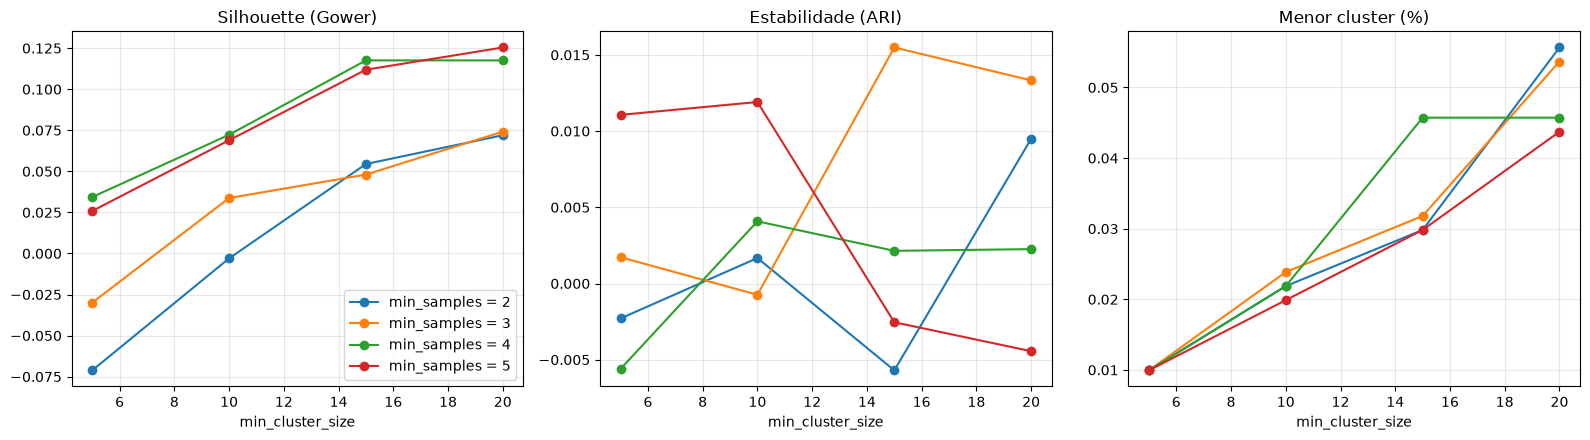

In [58]:
metricas = [
    ("silhouette_gower", "Silhouette (Gower)"),
    ("stability_ari", "Estabilidade (ARI)"),
    ("min_cluster_frac", "Menor cluster (%)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (col, titulo) in zip(axes, metricas):
    for ms, g in res.groupby("min_samples"):
        g = g.sort_values("min_cluster_size")

        ax.plot(
            g["min_cluster_size"],
            g[col],
            marker="o",
            label=f"min_samples = {ms}"
        )

    ax.set_title(titulo)
    ax.set_xlabel("min_cluster_size")
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

In [ ]:
#Salva as classes dessa segunda tentativa
classe_MDS = pd.DataFrame(labels_MDS, columns=["Classe_HDBS_MDS"])
classe_MDS.to_csv('dados/Classe_HDBS_MDS.csv', index=False)
classe_MDS

,Classe_HDBS_MDS
0,1
1,3
2,2
3,1
4,3
5,1
6,-1
7,1
8,1
9,1


# Modelo Final

PRA ADICIONAR NO DF ORIGINAL VVVVV

In [ ]:
#HDBS com as dimensoes do MDS
hdbs2 = HDBSCAN(min_cluster_size=15, min_samples=5, cluster_selection_method="eom", copy=True)
labels_MDS = hdbs2.fit_predict(teste_MDS)
labels_MDS

array([ 1,  3,  2,  1,  3,  1, -1,  1,  1,  1,  1,  1,  1,  3,  3,  1,  1,
        0,  1,  3,  3, -1,  3,  3,  3, -1,  1,  1,  1, -1,  3,  3,  1,  1,
        1, -1,  1,  1,  1,  1,  3,  1,  1,  1,  1,  1,  3,  1,  2,  1, -1,
       -1,  1,  1, -1, -1,  4, -1,  1,  1,  1,  1,  1, -1,  1,  1,  1, -1,
        1, -1, -1,  1,  1, -1,  1,  1, -1,  1,  1, -1,  1,  1,  1,  3, -1,
        1,  1,  1, -1,  3,  3,  3,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1,
        1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  3, -1, -1,  3, -1, -1,  1,
        1, -1,  1,  4, -1,  4, -1,  1, -1, -1, -1,  3,  1,  2,  4, -1, -1,
       -1, -1,  1,  1, -1,  1, -1, -1, -1, -1,  2,  3,  3, -1, -1,  1,  3,
        4,  4,  2, -1, -1,  4, -1,  1, -1,  3,  3, -1,  3,  3,  3,  3, -1,
       -1,  1,  3,  1, -1,  2, -1, -1, -1,  4,  1,  1, -1, -1, -1, -1,  1,
       -1,  1,  1, -1,  1, -1, -1,  1,  4, -1, -1,  2, -1, -1,  1, -1, -1,
        2, -1, -1,  1,  1

In [ ]:
df_copy["Classe"] = labels_MDS
df_copy

,Borda,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23,Cores_1,Cores_2,Cores_3,Cores_4,Cores_5,Cores_6,Cores_7,Textura_1,Textura_2,Forma_1,Forma_2,Forma_4,Forma_6,Brilho_0,Brilho_1,Brilho_2,Brilho_4,GRAM_Levedura,GRAM_Levedura?não,GRAM_Negativo,GRAM_Positivo,Classe
0,0.0,0.0,1.0,0,0.00,0,0,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.00,0.00,1,1,1,3,1.0,3.0,0,2.767,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1
1,0.0,0.0,0.0,0,2.33,0,0,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,2.80,3.00,1,3,3,2,3.0,3.0,0,12.678,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,3
2,0.0,0.0,0.0,0,3.50,0,0,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,2.00,2.50,1,3,3,3,3.0,3.0,3,6.870,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,0,0,0,1,2
3,0.0,0.0,1.0,0,0.00,0,0,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.00,0.00,1,0,0,0,0.0,1.0,0,2.728,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1
4,0.0,0.0,0.0,0,1.75,0,0,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.20,1,2,3,0,3.0,3.0,3,11.353,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,3
5,0.0,0.0,0.0,0,0.00,0,1,1.25,0.01,0.02,-0.03,0.87,0.48,0.23,0.35,0,0.00,0.00,1,1,0,3,0.0,0.0,0,3.209,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,0,1,1
6,0.0,0.0,0.0,0,2.25,0,0,1.33,0.01,0.11,-0.03,0.29,0.22,0.15,0.19,1,0.00,0.00,1,0,1,0,3.0,3.0,0,16.151,0,0,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0,1,0,-1
7,0.0,0.0,0.0,0,2.50,0,1,1.40,0.00,0.14,-0.01,0.52,0.23,0.16,0.16,1,0.00,0.00,1,0,0,0,0.0,0.0,0,8.512,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,1
8,0.0,0.0,1.0,0,0.00,0,0,1.50,0.01,0.13,0.00,1.36,0.63,0.24,0.05,1,0.00,1.33,1,0,0,3,0.0,0.0,0,2.033,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1
9,0.0,0.0,1.0,0,2.25,0,1,1.25,0.01,0.12,-0.01,0.56,0.21,0.17,0.15,1,0.00,0.00,1,0,1,3,1.0,0.0,0,35.659,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,1


In [ ]:
#PRA REMOVER CLASSE
df_copy = df_copy.drop(columns=["Classe"])
df_copy

,Borda,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23,Cores_1,Cores_2,Cores_3,Cores_4,Cores_5,Cores_6,Cores_7,Textura_1,Textura_2,Forma_1,Forma_2,Forma_4,Forma_6,Brilho_0,Brilho_1,Brilho_2,Brilho_4,GRAM_Levedura,GRAM_Levedura?não,GRAM_Negativo,GRAM_Positivo
0,0.0,0.0,1.0,0,0.00,0,0,1.20,0.00,0.00,-0.01,0.76,0.54,0.74,0.06,1,0.00,0.00,1,1,1,3,1.0,3.0,0,2.767,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
1,0.0,0.0,0.0,0,2.33,0,0,1.20,-0.01,0.13,-0.04,0.28,0.10,0.09,0.04,0,2.80,3.00,1,3,3,2,3.0,3.0,0,12.678,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
2,0.0,0.0,0.0,0,3.50,0,0,1.38,0.00,0.43,0.01,0.12,0.26,0.27,0.14,0,2.00,2.50,1,3,3,3,3.0,3.0,3,6.870,0,1,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,0,0,0,1
3,0.0,0.0,1.0,0,0.00,0,0,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0.00,0.00,1,0,0,0,0.0,1.0,0,2.728,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
4,0.0,0.0,0.0,0,1.75,0,0,1.20,0.00,0.10,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.20,1,2,3,0,3.0,3.0,3,11.353,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
5,0.0,0.0,0.0,0,0.00,0,1,1.25,0.01,0.02,-0.03,0.87,0.48,0.23,0.35,0,0.00,0.00,1,1,0,3,0.0,0.0,0,3.209,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,0,1
6,0.0,0.0,0.0,0,2.25,0,0,1.33,0.01,0.11,-0.03,0.29,0.22,0.15,0.19,1,0.00,0.00,1,0,1,0,3.0,3.0,0,16.151,0,0,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0,0,0,1,0
7,0.0,0.0,0.0,0,2.50,0,1,1.40,0.00,0.14,-0.01,0.52,0.23,0.16,0.16,1,0.00,0.00,1,0,0,0,0.0,0.0,0,8.512,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1
8,0.0,0.0,1.0,0,0.00,0,0,1.50,0.01,0.13,0.00,1.36,0.63,0.24,0.05,1,0.00,1.33,1,0,0,3,0.0,0.0,0,2.033,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0
9,0.0,0.0,1.0,0,2.25,0,1,1.25,0.01,0.12,-0.01,0.56,0.21,0.17,0.15,1,0.00,0.00,1,0,1,3,1.0,0.0,0,35.659,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1


In [ ]:
MORFOLOGIA = [
    "GRAM",
    "Cores",
    "Borda", 
    "Textura",
    "Forma",
    "Brilho",
    "Muco", 
    "Relevo",
    "Atividade 03",
    "Atividade 04",
    "Atividade 16"
]

NUM_COLS = [
    "Atividade 02",
    "Atividade 05",
    "Atividade 06",
    "Atividade 07",
    "Atividade 08",
    "Atividade 09",
    "Atividade 10",
    "Atividade 11",
    "Atividade 12",
    "Atividade 14",
    "Atividade 15",
    "Atividade 13",
    "Atividade 01",
    "Atividade 17",
    "Atividade 18",
    "Atividade 19",
    "Atividade 20",
    "Atividade 21",
    "Atividade 22",
    "Atividade 23",
]

In [ ]:
#CARACTERIZANDO OS CLUSTERS
dfOG = pd.read_csv("dados/Dados_REG_limpo_baseline.csv", sep="\t")

df_analise = dfOG.copy()
df_analise['Cluster'] = labels_MDS

#Tamanho de cada grupo
tamanho_grupos = df_analise['Cluster'].value_counts().sort_index()

percentual_grupos = (
    df_analise['Cluster'].value_counts(normalize=True).sort_index() * 100
)

tamanho = pd.DataFrame({
    'Quantidade': tamanho_grupos,
    'Percentual': percentual_grupos
})

#Perfil medio
perfil_atividades = df_analise.groupby('Cluster')[NUM_COLS].mean()

#Moda dos morfologicos
moda_morfologia = df_analise.groupby('Cluster')[MORFOLOGIA].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else None
)

caracterizacao = pd.concat([
    tamanho,
    perfil_atividades,
    moda_morfologia
], axis=1)

print(caracterizacao)

         Quantidade  Percentual  Atividade 02  Atividade 05  Atividade 06  \
Cluster                                                                     
-1              153   30.417495      0.857190      0.735621      0.077190   
 0               15    2.982107      2.262667      0.993333      0.005333   
 1              208   41.351889      0.540192      0.687740      0.146635   
 2               22    4.373757      1.970909      0.529545      0.005000   
 3               86   17.097416      1.640116      0.712442      0.015814   
 4               19    3.777336      0.860526      0.637895      0.047895   

         Atividade 07  Atividade 08  Atividade 09  Atividade 10  Atividade 11  \
Cluster                                                                         
-1           0.120392      0.011438      0.733137      0.456340      0.300980   
 0           0.144000      0.026000      0.489333      0.289333      0.270667   
 1           0.115769      0.017212      0.785913      0.48